# 02 — Protocolo experimental e piloto (Paula)

Executar em ordem, em CPU. Não é necessário instalar Transformers ou carregar pesos. Anexe o OCT-C8 e o CSV candidato/final da auditoria ao Kaggle.

Produz listas aninhadas para 17, 42 e 2026, código compartilhado de métricas, protocolo, demonstração de pré-processamento e um piloto real de integração com pixels reduzidos + regressão logística. **Esse piloto não é um resultado de DINOv3/RETFound nem um baseline do estudo.**

In [1]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata, sys
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

INPUT = Path('/kaggle/input')
for p in INPUT.rglob('*manifest*.csv'):
    print(p)

MANIFEST_PATH = Path('/kaggle/input/ALTERAR/octc8_manifest_candidate_v1.csv')
DATA_ROOT = Path('/kaggle/input/datasets/obulisainaren/retinal-oct-c8')
MANIFEST_APPROVED = False
REVIEWERS = ''
EXPECTED_MANIFEST_SHA256 = ''
RUN_REAL_PILOT = True
OUT_BASE = Path('/kaggle/working/oct_protocol')
CLASSES = ['AMD','CNV','CSR','DME','DR','DRUSEN','MH','NORMAL']
SEEDS = [17,42,2026]
PERCENTAGES = [1,5,10,25,100]


## 1. Validar a entrada

A seleção esperada tem 18.260/2.793/2.797 imagens. O código recusa alterações silenciosas. Não aprova dados por nome do arquivo. O checksum esperado deve vir do registro da versão aprovada, não ser preenchido automaticamente com o hash recém-calculado.

In [8]:
from pathlib import Path

csvs = sorted(Path("/kaggle/input").rglob("*.csv"))

print(f"CSVs encontrados: {len(csvs)}")
for i, arquivo in enumerate(csvs):
    print(f"[{i}] {arquivo}")

CSVs encontrados: 1
[0] /kaggle/input/datasets/paulaeduardadelima/octc8-project-manifests/octc8_manifest_audit_v1.csv


In [10]:
print("Arquivo:", MANIFEST_PATH)
print("Total de linhas:", len(manifest))
print("\nContagens por divisão:")
print(manifest.groupby("split").size())

for col in ["file_sha256", "pixel_sha256"]:
    duplicated = manifest.loc[
        manifest.duplicated(col, keep=False)
    ]

    print(f"\nHash: {col}")
    print("Arquivos em grupos duplicados:", len(duplicated))
    print("Grupos duplicados:", duplicated[col].nunique())

    if not duplicated.empty:
        display(
            duplicated[
                ["image_id", "relative_path", "class_name", "split", col]
            ].sort_values(col).head(12)
        )

# Detecta se foi selecionada uma tabela de decisões.
if "action" in manifest.columns:
    print("\nA entrada contém uma coluna de decisões:")
    print(manifest["action"].value_counts())

Arquivo: /kaggle/input/datasets/paulaeduardadelima/octc8-project-manifests/octc8_manifest_audit_v1.csv
Total de linhas: 24000

Contagens por divisão:
split
test      2800
train    18400
val       2800
dtype: int64

Hash: file_sha256
Arquivos em grupos duplicados: 288
Grupos duplicados: 144


,image_id,relative_path,class_name,split,file_sha256
15959,3427a591d639f676a5ff,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,00ca9d242b23815a83bc610092ac8c22215eeb3abe2b88...
23217,f87cf442229f968f2bf7,RetinalOCT_Dataset/RetinalOCT_Dataset/val/DRUS...,DRUSEN,val,00ca9d242b23815a83bc610092ac8c22215eeb3abe2b88...
6790,10922324baffdb94751e,RetinalOCT_Dataset/RetinalOCT_Dataset/train/CN...,CNV,train,010a9de14b7b4be01fd48de2e6fcdba152bccac52ced4f...
6789,8f8d7d09a84a9da19063,RetinalOCT_Dataset/RetinalOCT_Dataset/train/CN...,CNV,train,010a9de14b7b4be01fd48de2e6fcdba152bccac52ced4f...
10471,7edc5d7d182542ecba78,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DM...,DME,train,0426a930fc25597efc4b95026812a86a130317c2337680...
10472,95bb0c6b70ed40863637,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DM...,DME,train,0426a930fc25597efc4b95026812a86a130317c2337680...
15870,8d68296ccaa1507d4771,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,0770f0ddd4e872ad25037a695d8afddf5e322d056207b8...
15871,50dce21b580c3adcc176,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,0770f0ddd4e872ad25037a695d8afddf5e322d056207b8...
23208,ed905e00cbbcb4669e8c,RetinalOCT_Dataset/RetinalOCT_Dataset/val/DRUS...,DRUSEN,val,093201313c07c977f1f6d9dbf37dd74cf9783462fec985...
15985,cc8244802f48ee58de72,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,093201313c07c977f1f6d9dbf37dd74cf9783462fec985...



Hash: pixel_sha256
Arquivos em grupos duplicados: 288
Grupos duplicados: 144


,image_id,relative_path,class_name,split,pixel_sha256
15998,12c227a9073f0bc56f78,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,004a99e3ea3c39d6ca3e66526e3719d61fa9f4e40c1689...
23211,b3827bc6cc3d3848c4bd,RetinalOCT_Dataset/RetinalOCT_Dataset/val/DRUS...,DRUSEN,val,004a99e3ea3c39d6ca3e66526e3719d61fa9f4e40c1689...
14690,b1f59917581de3634318,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,03af23dba067b85701f965cf5be9d8b2dee1d1f186808b...
14689,69d8e4ef6e59d4e58da7,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,03af23dba067b85701f965cf5be9d8b2dee1d1f186808b...
6789,8f8d7d09a84a9da19063,RetinalOCT_Dataset/RetinalOCT_Dataset/train/CN...,CNV,train,04a6bfbbdda4a0fa6c524e6533064acdb03b2b9a024857...
6790,10922324baffdb94751e,RetinalOCT_Dataset/RetinalOCT_Dataset/train/CN...,CNV,train,04a6bfbbdda4a0fa6c524e6533064acdb03b2b9a024857...
14338,3dcfed198ec476c94f66,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,0943d2b7fff415d855eeb60dcc85d25131a62e38f1f69b...
14339,c2eef531b7d47faadc40,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,0943d2b7fff415d855eeb60dcc85d25131a62e38f1f69b...
16007,659f66d2004acb4e26e7,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,09bbba716b44f7c3335026e0448fdcae0bd535debf9954...
16008,1a4fc87343954c4943c6,RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR...,DRUSEN,train,09bbba716b44f7c3335026e0448fdcae0bd535debf9954...


In [11]:
MANIFEST_PATH = Path(
    "/kaggle/input/datasets/paulaeduardadelima/octc8-manifest-candidate-v1-csv/octc8_manifest_candidate_v1.csv"
)
assert MANIFEST_PATH.is_file(), 'Ajuste MANIFEST_PATH para o CSV anexado.'
manifest_bytes = MANIFEST_PATH.read_bytes()
manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()
print('SHA-256 da entrada:', manifest_hash)
manifest = pd.read_csv(MANIFEST_PATH, dtype={'image_id':str}, keep_default_na=False)
required = ['image_id','relative_path','class_name','class_id','split','file_sha256','pixel_sha256','read_ok']
assert set(required).issubset(manifest.columns)
assert manifest.image_id.is_unique and manifest.relative_path.is_unique
assert manifest[required].notna().all().all()
assert manifest.read_ok.astype(str).str.lower().eq('true').all()
assert set(manifest.split)=={'train','val','test'}
assert manifest.class_name.map(dict(zip(CLASSES,range(8)))).eq(manifest.class_id).all()
for col in ['file_sha256','pixel_sha256']:
    assert manifest[col].str.fullmatch('[0-9a-f]{64}').all()
    assert manifest[col].is_unique, 'Duplicata exata na entrada.'
for rel in manifest.relative_path:
    p=Path(rel)
    assert not p.is_absolute() and '..' not in p.parts
expected = pd.DataFrame({'train':[2300,2257,2300,2272,2300,2233,2300,2298],
                         'val':[350,347,350,349,350,348,350,349],
                         'test':[350,350,350,349,350,349,350,349]}, index=CLASSES)
counts=pd.crosstab(manifest.class_name,manifest.split).reindex(index=CLASSES,columns=['train','val','test'])
assert np.array_equal(counts.values,expected.values), 'Contagens diferentes: revisar a versão de dados.'
if MANIFEST_APPROVED:
    assert REVIEWERS.strip(), 'Registre os revisores reais.'
    assert EXPECTED_MANIFEST_SHA256 == manifest_hash, 'Checksum aprovado não corresponde.'
status='approved' if MANIFEST_APPROVED else 'provisional'
OUT=OUT_BASE / (manifest_hash[:12]+'_'+status)
OUT.mkdir(parents=True,exist_ok=True)

def save_json(path,obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    content=json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False)+'\n'
    path.write_text(content,encoding='utf-8')

(OUT/'manifest_used.csv').write_bytes(manifest_bytes)
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','Pillow','scikit-learn','matplotlib']}
save_json(OUT/'environment.json',{'python':platform.python_version(),'packages':versions})
save_json(OUT/'data_status.json',{'manifest_sha256':manifest_hash,'status':status,'reviewers':REVIEWERS})
display(counts)
print('Saídas:',OUT)


SHA-256 da entrada: 80d6eedc883410b47beeee6b1c72e72d69309ba38ac2595fc8f2590e6928103d


split,train,val,test
class_name,,,
AMD,2300,350,350
CNV,2257,347,350
CSR,2300,350,350
DME,2272,349,349
DR,2300,350,350
DRUSEN,2233,348,349
MH,2300,350,350
NORMAL,2298,349,349


Saídas: /kaggle/working/oct_protocol/80d6eedc8834_provisional


## 2. Módulo compartilhado

A próxima célula grava `src/oct_protocol.py`, que deverá ser commitado e importado pelos notebooks dos modelos. As métricas recebem uma tabela de probabilidades e uma referência de IDs; alinham por ID, recusam imagens ausentes/extras e validam a ordem das classes.

AUROC é calculada um-contra-o-resto usando probabilidades. Se uma classe não puder ser avaliada, seu AUROC será `null`; a média completa também será `null`, com uma média parcial identificada separadamente. Macro-F1 usa as oito classes fixas e zero para F1 indefinido. Recall sem suporte fica `null`.

In [12]:
MODULE_SOURCE = "import numpy as np\nimport pandas as pd\nfrom PIL import Image\nfrom sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score\n\nCLASSES = ['AMD','CNV','CSR','DME','DR','DRUSEN','MH','NORMAL']\n\ndef make_subsets(manifest, seeds=(17,42,2026), percentages=(1,5,10,25,100)):\n    train=manifest.loc[manifest.split=='train'].copy()\n    result={}\n    for seed in seeds:\n        permutations={}\n        for cls in range(8):\n            rows=train.loc[train.class_id==cls].sort_values('image_id').reset_index(drop=True)\n            rng=np.random.default_rng(np.random.SeedSequence([seed,cls]))\n            permutations[cls]=rows.iloc[rng.permutation(len(rows))]\n        previous=set()\n        for pct in percentages:\n            parts=[rows.iloc[:max(1,len(rows)*pct//100)] for rows in permutations.values()]\n            subset=pd.concat(parts).sort_values('image_id').reset_index(drop=True)\n            ids=set(subset.image_id)\n            assert previous.issubset(ids)\n            previous=ids\n            result[(seed,pct)]=subset\n        assert previous==set(train.image_id)\n    return result\n\ndef prepare_rgb(path):\n    # Imagem inteira; distorce a proporção original, sem recorte/padding.\n    with Image.open(path) as im:\n        return im.convert('RGB').resize((224,224),Image.Resampling.BICUBIC)\n\ndef normalize_rgb(image, mean, std):\n    mean=np.asarray(mean,dtype=np.float32); std=np.asarray(std,dtype=np.float32)\n    if mean.shape!=(3,) or std.shape!=(3,) or not np.isfinite(mean).all() or not np.isfinite(std).all() or (std<=0).any():\n        raise ValueError('Informe mean/std verificados para os três canais.')\n    x=np.asarray(image,dtype=np.float32)/255.0\n    if x.shape!=(224,224,3): raise ValueError('Esperado RGB 224x224.')\n    return ((x-mean)/std).transpose(2,0,1).copy()\n\ndef evaluate_predictions(reference, predictions):\n    columns=['p_'+c for c in CLASSES]\n    if not {'image_id','class_id'}.issubset(reference.columns): raise ValueError('Referência inválida.')\n    if not {'image_id',*columns}.issubset(predictions.columns): raise ValueError('Faltam probabilidades por classe.')\n    if not reference.image_id.is_unique or not predictions.image_id.is_unique: raise ValueError('IDs duplicados.')\n    if len(reference)==0 or set(reference.image_id)!=set(predictions.image_id): raise ValueError('IDs não correspondem.')\n    labels=reference.class_id.to_numpy()\n    if not np.isin(labels,np.arange(8)).all(): raise ValueError('Rótulos fora de 0..7.')\n    aligned=reference[['image_id','class_id']].merge(predictions[['image_id']+columns],on='image_id',validate='one_to_one')\n    y=aligned.class_id.to_numpy(dtype=int); p=aligned[columns].to_numpy(dtype=float)\n    if not np.isfinite(p).all() or (p<0).any() or (p>1).any() or not np.allclose(p.sum(1),1,atol=1e-5):\n        raise ValueError('Esperadas probabilidades finitas, entre 0 e 1, somando 1; não logits.')\n    pred=p.argmax(1)\n    cm=confusion_matrix(y,pred,labels=np.arange(8)); support=cm.sum(1)\n    recall=[float(cm[i,i]/support[i]) if support[i] else None for i in range(8)]\n    auc=[float(roc_auc_score((y==i).astype(int),p[:,i])) if 0<(y==i).sum()<len(y) else None for i in range(8)]\n    acc=float(accuracy_score(y,pred)); ba=float(np.mean([r for r in recall if r is not None]))\n    balanced=bool((support>0).all() and (support==support[0]).all())\n    if balanced and not np.isclose(acc,ba): raise AssertionError('Erro em métricas de conjunto balanceado.')\n    metrics={'n':len(y),'class_order':CLASSES,'macro_f1':float(f1_score(y,pred,labels=np.arange(8),average='macro',zero_division=0)),\n             'accuracy':acc,'balanced_accuracy':ba,'balanced_accuracy_scope':'classes_present',\n             'recall_per_class':dict(zip(CLASSES,recall)),'support':dict(zip(CLASSES,map(int,support))),\n             'auroc_per_class':dict(zip(CLASSES,auc)),\n             'auroc_macro':float(np.mean(auc)) if all(a is not None for a in auc) else None,\n             'auroc_macro_defined_classes':float(np.mean([a for a in auc if a is not None])) if any(a is not None for a in auc) else None,\n             'auroc_classes_defined':sum(a is not None for a in auc),\n             'balanced_support':balanced,'accuracy_minus_balanced_accuracy':acc-ba}\n    normalized=np.divide(cm,support[:,None],out=np.zeros_like(cm,dtype=float),where=support[:,None]!=0)\n    return metrics,pd.DataFrame(cm,index=CLASSES,columns=CLASSES),pd.DataFrame(normalized,index=CLASSES,columns=CLASSES)\n"
source_dir=OUT/'src'; source_dir.mkdir(exist_ok=True)
(source_dir/'oct_protocol.py').write_text(MODULE_SOURCE,encoding='utf-8')
# Carrega a versão recém-gerada, sem reutilizar módulos de outra execução.
namespace={}
exec(compile(MODULE_SOURCE,'oct_protocol.py','exec'),namespace)
make_subsets=namespace['make_subsets']
prepare_rgb=namespace['prepare_rgb']
normalize_rgb=namespace['normalize_rgb']
evaluate_predictions=namespace['evaluate_predictions']

## 3. Listas aninhadas e custo de anotação

Regra escolhida: `max(1, floor(n_classe × fração))`. A porcentagem é aplicada ao treino auditado de cada classe, sem forçar 23/115/230/575 imagens em todas. A ordenação inicial por ID garante estabilidade mesmo se o CSV mudar de ordem. Cada classe usa um gerador derivado de `(seed, class_id)`.

100% é salvo **uma única vez**, em ordem canônica. As três seeds apontam para esse arquivo; não representam três amostras de dados. Seeds de treinamento ainda podem variar quando o algoritmo é estocástico. Um classificador determinístico com dados/configuração idênticos deve rodar uma vez.

Validação contém **2.793 rótulos adicionais**, usados na seleção. O teste tem 2.797 rótulos reservados à avaliação final. “1%” descreve apenas o treino, não todo o custo de anotação.

In [13]:
subsets=make_subsets(manifest)
split_dir=OUT/'data/splits'; split_dir.mkdir(parents=True,exist_ok=True)
rows=[]; registry={}
for split in ['val','test']:
    fixed=manifest.loc[manifest.split==split].sort_values('image_id')
    fixed.to_csv(split_dir/f'{split}_fixed.csv',index=False)
for (seed,pct),subset in subsets.items():
    name='train_p100.csv' if pct==100 else f'train_p{pct:02d}_seed{seed}.csv'
    path=split_dir/name
    data=subset.to_csv(index=False).encode('utf-8')
    if path.exists(): assert path.read_bytes()==data, 'Arquivo anterior difere: crie outra versão.'
    else: path.write_bytes(data)
    assert set(subset.image_id).isdisjoint(manifest.loc[manifest.split!='train','image_id'])
    registry[f'p{pct:02d}_seed{seed}']={'file':name,'sha256':hashlib.sha256(data).hexdigest(),'n_train':len(subset)}
    for cls in CLASSES:
        rows.append({'seed':seed,'percent':pct,'class_name':cls,'n':int((subset.class_name==cls).sum())})
for seed in SEEDS:
    assert subsets[(seed,100)].image_id.tolist()==subsets[(17,100)].image_id.tolist()
for split in ['val','test']:
    path=split_dir/f'{split}_fixed.csv'
    registry[split]={'file':path.name,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
save_json(split_dir/'registry.json',{'manifest_sha256':manifest_hash,'status':status,'subsets':registry})
summary=pd.DataFrame(rows)
summary.to_csv(split_dir/'counts.csv',index=False)
display(summary.query('seed==17').pivot(index='class_name',columns='percent',values='n').reindex(CLASSES))
totals=summary.query('seed==17').groupby('percent')['n'].sum().to_frame('train_labels')
totals['validation_labels']=len(manifest.query("split=='val'"))
totals['train_plus_validation']=totals.train_labels+totals.validation_labels
totals.to_csv(split_dir/'annotation_budget.csv'); display(totals)


percent,1,5,10,25,100
class_name,,,,,
AMD,23,115,230,575,2300
CNV,22,112,225,564,2257
CSR,23,115,230,575,2300
DME,22,113,227,568,2272
DR,23,115,230,575,2300
DRUSEN,22,111,223,558,2233
MH,23,115,230,575,2300
NORMAL,22,114,229,574,2298


,train_labels,validation_labels,train_plus_validation
percent,,,
1,180,2793,2973
5,910,2793,3703
10,1824,2793,4617
25,4564,2793,7357
100,18260,2793,21053


## 4. Processamento de imagens

Política geométrica proposta: converter para RGB (replica cinza), redimensionar a imagem inteira para 224×224 com PIL bicúbica, sem corte central e sem augmentations na extração congelada. Essa operação altera a proporção das imagens retangulares; registrar como limitação. Não foi otimizada no teste.

A normalização deve vir do processador/configuração do checkpoint exato. Não assumir que RETFound e DINOv3 usam a mesma. Preencha os registros abaixo antes da extração principal. No DINOv3, o `processor.to_dict()` salvo no `run_spec.json` do notebook inicial contém os parâmetros. Para RETFound, Ana Júlia deve conferir a implementação e revisão utilizadas.

Usar **ou** `normalize_rgb` **ou** o processador oficial para normalização, evitando normalizar duas vezes. Ao entregar a imagem já 224×224 ao processador DINOv3, desativar novo resize/crop e manter `use_fast=True`, conforme o teste anterior.

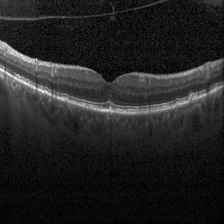

In [14]:
MODEL_NORMALIZATION = {
    'dinov3_vitl16': {'mean':None,'std':None,'checkpoint_revision':None,'evidence':None},
    'retfound_mae_oct': {'mean':None,'std':None,'checkpoint_revision':None,'evidence':None},
}
# Exemplo após ler run_spec.json, sem baixar pesos:
# spec=json.loads(Path('/kaggle/input/SEU_BACKUP/run_spec.json').read_text())
# MODEL_NORMALIZATION['dinov3_vitl16'] = {
#     'mean':spec['processor']['image_mean'], 'std':spec['processor']['image_std'],
#     'checkpoint_revision':spec['revision'], 'evidence':'run_spec.json do teste DINOv3'}

def model_input(path,model_name):
    cfg=MODEL_NORMALIZATION[model_name]
    if any(cfg[k] is None for k in ['mean','std','checkpoint_revision','evidence']):
        raise ValueError('Registre a normalização e a evidência do checkpoint antes da extração.')
    return normalize_rgb(prepare_rgb(path),cfg['mean'],cfg['std'])

save_json(OUT/'preprocessing.json',{
    'size':[224,224],'color':'RGB','resize':'PIL_BICUBIC_whole_image',
    'crop':False,'aspect_ratio_preserved':False,'augmentation_frozen_features':False,
    'normalization':MODEL_NORMALIZATION})
if DATA_ROOT.is_dir():
    example=subsets[(17,1)].iloc[0]
    display(prepare_rgb(DATA_ROOT/example.relative_path))
else:
    print('Anexe OCT-C8 antes de executar o piloto real.')


## 5. Testar as métricas com exemplos conhecidos

Testes sintéticos verificam cálculo, alinhamento por ID e rejeição de previsões inválidas. Não são medidas de desempenho dos modelos.

In [15]:
ref=pd.DataFrame({'image_id':[f'synthetic_{i}' for i in range(16)],'class_id':np.tile(np.arange(8),2)})
probs=np.eye(8)[ref.class_id.to_numpy()]
pred=pd.DataFrame(probs,columns=['p_'+c for c in CLASSES]); pred.insert(0,'image_id',ref.image_id)
m,cm,cmn=evaluate_predictions(ref,pred.sample(frac=1,random_state=17))
assert m['macro_f1']==1 and m['accuracy']==1 and m['auroc_macro']==1
bad=pred.copy(); bad.loc[0,'image_id']='extra_id'
try: evaluate_predictions(ref,bad)
except ValueError: pass
else: raise AssertionError('Não rejeitou IDs incorretos.')
bad=pred.copy(); bad.loc[0,'p_AMD']=2
try: evaluate_predictions(ref,bad)
except ValueError: pass
else: raise AssertionError('Não rejeitou probabilidades inválidas.')
short=ref.iloc[:1]; short_pred=pred.iloc[:1]
missing,_,_=evaluate_predictions(short,short_pred)
assert missing['auroc_macro'] is None and missing['recall_per_class']['CNV'] is None
# Caso desbalanceado: prevê apenas classe 0.
u=pd.DataFrame({'image_id':['u0','u1','u2'],'class_id':[0,0,1]})
p=pd.DataFrame(np.tile([1.,0,0,0,0,0,0,0],(3,1)),columns=['p_'+c for c in CLASSES]); p.insert(0,'image_id',u.image_id)
um,_,_=evaluate_predictions(u,p)
assert np.isclose(um['accuracy'],2/3) and np.isclose(um['balanced_accuracy'],.5)
save_json(OUT/'metrics_self_test.json',{'passed':True,'synthetic_only':True})
print('Testes de métricas concluídos.')


Testes de métricas concluídos.


## 6. Piloto real em CPU: treino 1%, seed 17 → validação fixa

Este piloto testa leitura, RGB/224, ajuste somente no treino, seleção somente na validação e exportação. Usa pixels RGB reduzidos para 8×8 como atributos e regressão logística; **não testa os embeddings ou a normalização dos modelos pré-treinados**. Não abre imagens do teste.

O `StandardScaler` é ajustado somente no subconjunto de treino. A validação completa é usada para escolher C por macro-F1. Um aviso de convergência invalida a configuração; não esconder avisos. Não interpretar as métricas como comparação científica entre modelos.

Imagens lidas: 500
Imagens lidas: 1000
Imagens lidas: 1500
Imagens lidas: 2000
Imagens lidas: 2500


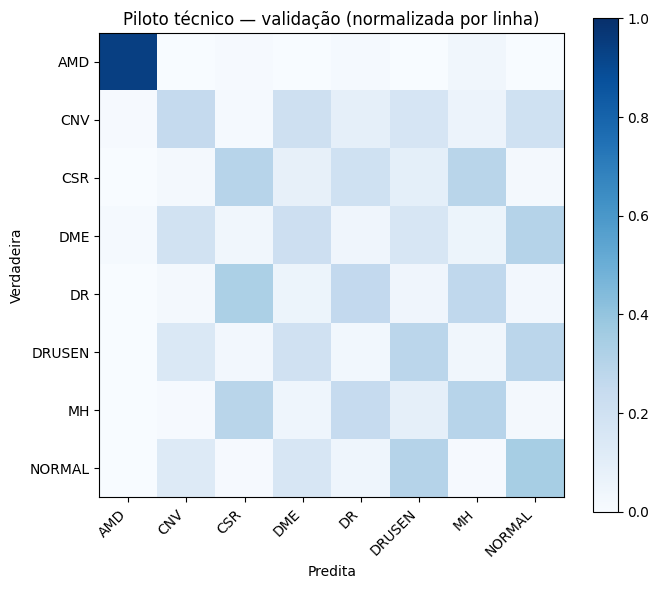

C escolhido: 1.0


n                                                                                2793
class_order                              [AMD, CNV, CSR, DME, DR, DRUSEN, MH, NORMAL]
macro_f1                                                                     0.361519
accuracy                                                                     0.360902
balanced_accuracy                                                            0.360674
balanced_accuracy_scope                                               classes_present
recall_per_class                    {'AMD': 0.94, 'CNV': 0.25360230547550433, 'CSR...
support                             {'AMD': 350, 'CNV': 347, 'CSR': 350, 'DME': 34...
auroc_per_class                     {'AMD': 0.992916203730776, 'CNV': 0.6770131085...
auroc_macro                                                                  0.760627
auroc_macro_defined_classes                                                  0.760627
auroc_classes_defined                                 

In [16]:
if RUN_REAL_PILOT:
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.exceptions import ConvergenceWarning
    import warnings, time
    pilot_dir=OUT/'pilot_pixels'; pilot_dir.mkdir(exist_ok=True)
    pilot_train=subsets[(17,1)].copy()
    pilot_val=manifest.loc[manifest.split=='val'].sort_values('image_id').copy()
    assert set(pilot_train.split)=={'train'} and set(pilot_val.split)=={'val'}
    def pixel_features(frame):
        result=[]
        for i,row in enumerate(frame.itertuples(),1):
            path=DATA_ROOT/row.relative_path
            assert hashlib.sha256(path.read_bytes()).hexdigest()==row.file_sha256, 'Imagem diferente da auditada.'
            rgb=prepare_rgb(path)
            result.append(np.asarray(rgb.resize((8,8),Image.Resampling.BOX),dtype=np.float32).ravel()/255.)
            if i%500==0: print('Imagens lidas:',i)
        return np.stack(result)
    Xtrain=pixel_features(pilot_train); Xval=pixel_features(pilot_val)
    trials=[]; best=None
    for C in [.01,.1,1.]:
        start=time.perf_counter()
        clf=make_pipeline(StandardScaler(),LogisticRegression(C=C,solver='lbfgs',max_iter=1000,random_state=17))
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter('always',ConvergenceWarning)
            clf.fit(Xtrain,pilot_train.class_id)
        converged=not any(issubclass(w.category,ConvergenceWarning) for w in captured)
        for w in captured: print(type(w.message).__name__,str(w.message))
        if not converged:
            trials.append({'C':C,'valid':False,'reason':'convergence_warning','seconds':time.perf_counter()-start})
            continue
        assert np.array_equal(clf.classes_,np.arange(8))
        prediction=pd.DataFrame(clf.predict_proba(Xval),columns=['p_'+c for c in CLASSES])
        prediction.insert(0,'image_id',pilot_val.image_id.to_numpy())
        metrics,confusion,normalized=evaluate_predictions(pilot_val,prediction)
        trials.append({'C':C,'valid':True,'macro_f1':metrics['macro_f1'],'seconds':time.perf_counter()-start})
        # Empate: menor C, pois a grade está em ordem crescente.
        if best is None or metrics['macro_f1']>best[0]:
            best=(metrics['macro_f1'],C,metrics,prediction,confusion,normalized)
    save_json(pilot_dir/'trials.json',trials)
    assert best is not None, 'Nenhuma configuração convergiu; investigar antes de continuar.'
    _,chosen_C,metrics,prediction,confusion,normalized=best
    save_json(pilot_dir/'validation_metrics.json',metrics)
    save_json(pilot_dir/'run_config.json',{'purpose':'technical_pixel_pilot_not_model_result','C':chosen_C,
              'seed':17,'fraction':.01,'manifest_sha256':manifest_hash,'data_status':status,
              'feature':'RGB224_then_BOX8x8_flatten_div255','scaler_fit':'train_only','test_used':False})
    prediction.to_csv(pilot_dir/'validation_predictions.csv',index=False)
    confusion.to_csv(pilot_dir/'confusion_counts.csv'); normalized.to_csv(pilot_dir/'confusion_row_normalized.csv')
    import matplotlib.pyplot as plt
    fig,ax=plt.subplots(figsize=(7,6)); im=ax.imshow(normalized,vmin=0,vmax=1,cmap='Blues')
    ax.set(xticks=range(8),yticks=range(8),xticklabels=CLASSES,yticklabels=CLASSES,
           xlabel='Predita',ylabel='Verdadeira',title='Piloto técnico — validação (normalizada por linha)')
    plt.setp(ax.get_xticklabels(),rotation=45,ha='right'); fig.colorbar(im,ax=ax)
    fig.tight_layout(); fig.savefig(pilot_dir/'confusion.png',dpi=150); plt.show()
    print('C escolhido:',chosen_C); display(pd.Series(metrics))
else:
    print('Piloto real não executado. Listas e métricas podem ser preparadas em CPU.')


## 7. Protocolo de comparação a revisar em dupla

Proposta para a comparação principal com extratores congelados: os mesmos subconjuntos, classificador linear multinomial, StandardScaler ajustado apenas no treino e grade `C=[0.001,0.01,0.1,1,10]`, solver lbfgs, máximo 1000 iterações. Selecionar por macro-F1 de validação; empate favorece menor C. Registrar falhas e tempos; qualquer ampliação da grade precisa valer para todos os extratores comparáveis.

CNN do zero e fine-tuning têm outra família de otimização. Sugestão a aprovar: até 5 configurações por modelo/fração/seed, até 30 épocas por configuração, early stopping com paciência 5 em macro-F1 de validação, mesma regra de checkpoint e sem alterar a busca após observar o teste. Registrar GPU-horas, parâmetros, batch size e resolução; igual número de configurações não garante igual custo computacional. Este notebook documenta esses limites, mas não implementa os treinamentos neurais.

As configurações escolhidas por validação devem ser registradas antes da avaliação final. Em 100%, rodar apenas uma vez o classificador determinístico com o mesmo extrator e entrada canônica. Não registrar cópias como três repetições independentes.

O teste auditado tem suportes 349/350: accuracy e balanced accuracy **não precisam coincidir**. O avaliador verifica igualdade apenas se todos os suportes forem iguais.

Diferenças de arquitetura, quantidade/origem de dados, objetivo de pré-treinamento e adaptações de processamento impedem atribuir toda diferença de desempenho exclusivamente a “geral versus especializado”. Não há independência por paciente ou do pré-treinamento comprovada.

In [17]:
protocol={
 'status':'draft_for_joint_review','data_status':status,'manifest_sha256':manifest_hash,
 'seeds':SEEDS,'percentages':PERCENTAGES,'rounding':'max(1,floor(class_train_n*pct/100))',
 'nested':True,'primary_metric':'macro_f1','selection_split':'val','test_for_final_only':True,
 'frozen_linear':{'C':[.001,.01,.1,1.,10.],'solver':'lbfgs','max_iter':1000,
                  'standard_scaler_fit':'subset_train_only','tie_break':'smallest_C','max_trials':5},
 'neural_budget_proposal':{'max_trials':5,'max_epochs':30,'early_stopping_patience':5},
 'full_data_deterministic_repeats':1,'validation_annotation_count':2793,'test_annotation_count':2797,
 'normalization_pending':[k for k,v in MODEL_NORMALIZATION.items() if any(v[f] is None for f in ['mean','std','checkpoint_revision','evidence'])],
 'limitations':['patient_separation_unverified','pretraining_independence_unverified','near_duplicates_not_excluded','resize_changes_aspect_ratio'],
}
save_json(OUT/'protocol.json',protocol)
report=f"""# Protocolo experimental — registro

Status do protocolo: proposta para revisão conjunta.
Status dos dados: {status}.
SHA-256 do manifesto: {manifest_hash}.

A redução de rótulos se aplica apenas ao treino auditado. As 2.793 imagens de validação
continuam rotuladas e são utilizadas para escolher configurações. Portanto, o orçamento
de anotação para ajuste e seleção soma os rótulos do subconjunto de treino e os 2.793
rótulos de validação. Os 2.797 rótulos de teste são reservados à avaliação final.

As divisões são fixas e os subconjuntos aninhados são compartilhados por todos os modelos.
As contagens exatas estão em data/splits/counts.csv e annotation_budget.csv.
Em 100%, não repetir um classificador determinístico com a mesma configuração e dados.

O piloto de pixels testa integração e não constitui resultado de DINOv3 ou RETFound.
A normalização específica e o orçamento de busca ainda exigem revisão conjunta.
O teste levemente desbalanceado não exige igualdade de accuracy e balanced accuracy.
As limitações de paciente, pré-treinamento e geometria estão em protocol.json.

## Próximas ações
- Paula: preservar listas, módulo de métricas, configuração e saídas do piloto.
- Ana Júlia: revisar métricas e conferir normalização/checkpoint RETFound.
- Ambas: registrar decisões de dados e orçamento; usar a mesma versão das listas.
- Antes dos experimentos: confirmar manifesto final e normalizações; registrar o protocolo aprovado.
"""
(OUT/'protocol_notes.md').write_text(report,encoding='utf-8')
print('Protocolo e texto para o relatório salvos.')


Protocolo e texto para o relatório salvos.


## 8. Exportar e preservar

O ZIP contém apenas a pasta deste protocolo, sem imagens ou pesos. Baixe-o ou preserve as saídas da versão do notebook. Commitar `src/oct_protocol.py`, listas/registry/contagens em `data/splits/` sob uma pasta de versão, e protocolo/ambiente/piloto em `reports/protocol/`. Não substituir listas de uma versão anterior silenciosamente. Remova a saída Base64 antes de commitar o notebook.

A conclusão desta etapa exige listas verificadas, métricas testadas, piloto real concluído e registro das normalizações e do orçamento aprovados. O notebook não declara essas aprovações automaticamente.

Referências técnicas: [scikit-learn — AUROC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), [DINOv3/Transformers](https://huggingface.co/docs/transformers/model_doc/dinov3), [RETFound](https://github.com/rmaphoh/RETFound).

In [18]:
from zipfile import ZipFile,ZIP_DEFLATED
import base64
from IPython.display import HTML
checksums={str(p.relative_to(OUT)):hashlib.sha256(p.read_bytes()).hexdigest()
           for p in sorted(OUT.rglob('*')) if p.is_file() and p.name!='checksums.json'}
save_json(OUT/'checksums.json',checksums)
zip_path=OUT_BASE/f'{OUT.name}.zip'
with ZipFile(zip_path,'w',ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(OUT)))
print('Pacote:',zip_path,'MB:',round(zip_path.stat().st_size/1024**2,2))
if zip_path.stat().st_size < 15*1024**2:
    b64=base64.b64encode(zip_path.read_bytes()).decode('ascii')
    display(HTML(f'<a download="{zip_path.name}" href="data:application/zip;base64,{b64}">Baixar protocolo e listas</a>'))
else:
    print('Baixe o ZIP pelas saídas salvas do notebook; arquivo grande para link embutido.')


Pacote: /kaggle/working/oct_protocol/80d6eedc8834_provisional.zip MB: 7.2
